# 19. Interpretabilidad global y local: SHAP y LIME

La sección 5.3 del enunciado pide, para el mejor modelo de cada tarea, una explicación **global** (resumen de
valores de Shapley) y **local** (dos observaciones: una bien predicha y una con error alto), y comparar SHAP con
LIME en XGBoost.

- **Clasificación:** el campeón con mejor validación anterior a 2016 es XGBoost con class_weight (cap. 17).
- **Regresión:** el mejor modelo **benchmark** es XGBoost (campeón: TPE); el mejor modelo **global** es el
  propuesto A+B v2 (cap. 18 y 22). Se aplica SHAP exacto para árboles (TreeSHAP) a XGBoost y, como A+B v2 es
  una combinación ponderada de modelos, se explica por sus pesos por miembro (19.4).

**Qué modelo se explica.** En el origen móvil hay un modelo por año. Se explica el del **primer origen**:
entrenado con todo lo anterior a 2021, con los hiperparámetros fijados antes de 2016, y aplicado a los 12 meses
de 2021 que ese modelo pronosticó. Los modelos de los años siguientes tienen la misma estructura y solo agregan
datos.

**Valores de Shapley.** La contribución de la variable j a la predicción f(x) es su aporte marginal promedio
sobre todos los órdenes posibles de incorporar las variables. Es la única atribución que cumple **eficiencia**
(las contribuciones suman f(x) − E[f(X)]), **simetría** (dos variables intercambiables reciben lo mismo),
**jugador nulo** y **aditividad** (la atribución de una suma de modelos es la suma de atribuciones). TreeSHAP
las calcula de forma exacta en tiempo polinómico para ensambles de árboles (Lundberg et al., 2020).

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# SHAP, LIME y los mejores modelos de cada tarea
import warnings
warnings.filterwarnings("ignore")
import shap
from lime.lime_tabular import LimeTabularExplainer
from src import benchmark as bm, resultados_e2 as r2
import json
ev_, X, info, tr, gp, te = datos.panel_completo()          # panel con corte 2021-01 = primer origen del origen móvil
y = info["y"].astype(float); tm = info["tm"]
te = te[tm[te] < datos.indice_mes(["2022-01-01"])[0]]        # los 12 meses que pronostica el primer origen
cr = r2.campeones_om("reg"); cc_ = r2.campeones_om("clf")
vr = cr[cr.modelo == "XGBoost"].iloc[0].variante
mejor_reg = {"tarea": "reg", "modelo": "XGBoost", "balanceo": None, "etiqueta": f"XGBoost · {r2.ABREV_OPT[vr]}",
             "params_finales": json.load(open(r2.OM / "hp_bench" / f"{r2._slug('XGBoost', vr)}.json"))["params"]}
fc = cc_.iloc[0]
mejor_clf = {"tarea": "clf", "modelo": fc.modelo, "balanceo": fc.variante, "etiqueta": fc.etiqueta,
             "params_finales": json.load(open(r2.OM / "hp_clf" / f"{r2._slug(fc.modelo, fc.variante, r2.TPE)}.json"))["params"]}
print("Regresión:", mejor_reg["etiqueta"], "| Clasificación:", mejor_clf["etiqueta"], "| filas explicadas:", len(te))

Regresión: XGBoost · TPE | Clasificación: XGBoost · c_weight | filas explicadas: 1956


In [3]:
# Reajusta el mejor modelo de cada tarea y calcula los valores SHAP (TreeExplainer)
def ajustar(r):
    if r["tarea"] == "reg":
        m = bm.construir("reg", r["modelo"], r["params_finales"], X.columns, n_jobs=2).fit(X.iloc[tr], y[tr])
        pipe = m.regressor_
    else:
        m = bm.construir("clf", r["modelo"], r["params_finales"], X.columns, r["balanceo"], n_jobs=2).fit(X.iloc[tr], (y[tr] >= 1).astype(int))
        pipe = m
    prep, est = pipe.named_steps["prep"], pipe.named_steps["modelo"]
    nombres = list(prep.get_feature_names_out())
    return m, prep, est, nombres

m_reg, prep_r, xgb_r, nombres = ajustar(mejor_reg)
m_clf, prep_c, xgb_c, _ = ajustar(mejor_clf)
Xtr_r = prep_r.transform(X.iloc[tr]); Xte_r = prep_r.transform(X.iloc[te])
Xtr_c = prep_c.transform(X.iloc[tr]); Xte_c = prep_c.transform(X.iloc[te])
rng = np.random.default_rng(cfg.SEMILLA)
muestra = np.arange(len(te))                                    # todas las filas de 2021 para el resumen global
exp_r = shap.TreeExplainer(xgb_r); sv_r = exp_r(pd.DataFrame(Xte_r[muestra], columns=nombres))
exp_c = shap.TreeExplainer(xgb_c); sv_c = exp_c(pd.DataFrame(Xte_c[muestra], columns=nombres))
print("SHAP calculado (escala log1p para regresión, log-odds para clasificación)")

SHAP calculado (escala log1p para regresión, log-odds para clasificación)


## 19.1 Interpretabilidad global (summary plot)

Cada punto es una celda-mes de la prueba; el eje horizontal es su valor SHAP (efecto sobre la predicción) y
el color, el valor de la variable (rojo = alto). Regresión en escala log1p (la escala en que se entrena);
clasificación en log-odds.

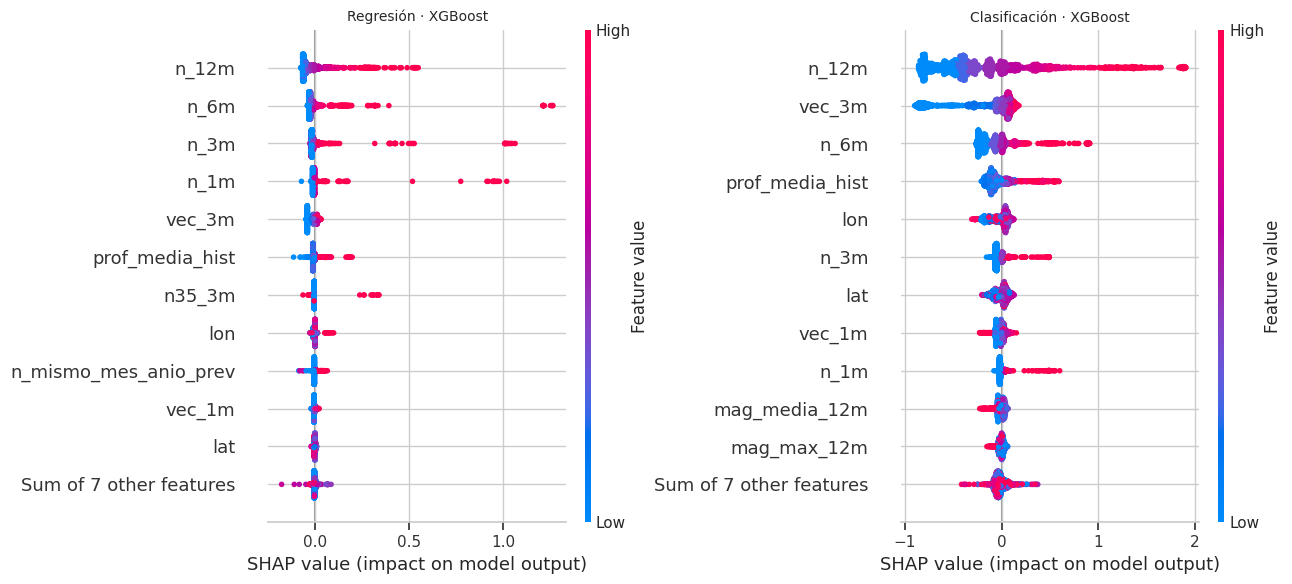

In [4]:
# Gráficos de resumen SHAP (beeswarm) de regresión y clasificación
fig = plt.figure(figsize=(13, 6))
ax1 = fig.add_subplot(1, 2, 1); shap.plots.beeswarm(sv_r, max_display=12, show=False, plot_size=None); ax1.set_title("Regresión · XGBoost", fontsize=10)
ax2 = fig.add_subplot(1, 2, 2); shap.plots.beeswarm(sv_c, max_display=12, show=False, plot_size=None); ax2.set_title("Clasificación · XGBoost", fontsize=10)
plt.tight_layout(); eda.guardar_figura(fig, "e2_shap_resumen.png"); plt.show()

In [5]:
# Importancia global: |SHAP| medio por variable
imp = pd.DataFrame({"variable": nombres, "|SHAP| medio regresión": np.abs(sv_r.values).mean(0), "|SHAP| medio clasificación": np.abs(sv_c.values).mean(0)})
imp["% regresión"] = 100 * imp["|SHAP| medio regresión"] / imp["|SHAP| medio regresión"].sum()
imp["% clasificación"] = 100 * imp["|SHAP| medio clasificación"] / imp["|SHAP| medio clasificación"].sum()
imp = imp.sort_values("|SHAP| medio regresión", ascending=False)
eda.guardar_tabla(imp, "e2_shap_importancia.csv")
imp.round(4).head(12)

,variable,|SHAP| medio regresión,|SHAP| medio clasificación,% regresión,% clasificación
3,n_12m,0.0665,0.4845,32.629299,36.585499
2,n_6m,0.0392,0.1557,19.216900,11.753900
1,n_3m,0.0246,0.0538,12.049200,4.065800
0,n_1m,0.0170,0.0311,8.321700,2.349500
7,vec_3m,0.0147,0.2065,7.218900,15.591200
13,prof_media_hist,0.0130,0.1161,6.381500,8.769800
4,n35_3m,0.0056,0.0008,2.748800,0.056900
17,lon,0.0043,0.0712,2.091000,5.377400
8,n_mismo_mes_anio_prev,0.0037,0.0172,1.799100,1.300100
6,vec_1m,0.0035,0.0316,1.709400,2.386300


In [6]:
# Lectura de la importancia global
top = imp.variable.iloc[:3].tolist()
rho = stats.spearmanr(imp["|SHAP| medio regresión"], imp["|SHAP| medio clasificación"])[0]
corr_dir = {v: stats.spearmanr(Xte_r[muestra][:, nombres.index(v)], sv_r.values[:, nombres.index(v)])[0] for v in top}
md(f"- Las tres variables más influyentes en regresión son **{top[0]}**, **{top[1]}** y **{top[2]}**, que juntas explican el "
   f"{imp['% regresión'].iloc[:3].sum():.0f} % de la magnitud total de las contribuciones. La importancia en las dos tareas está muy "
   f"alineada (Spearman = {rho:.2f}): las dos preguntas («cuántos» y «si habrá») dependen de lo mismo.\n"
   f"- **Dirección.** La correlación entre el valor de la variable y su SHAP es "
   + ", ".join(f"{v}: {c:+.2f}" for v, c in corr_dir.items()) +
   ". Más actividad reciente en la celda → más sismos esperados el mes siguiente: es la **persistencia** de la sismicidad "
   "(réplicas y enjambres, cap. 7) y el agrupamiento espacial (cap. 8) que el EDA había anticipado.\n"
   "- Las variables de calendario y de ubicación pesan poco frente a la historia de conteos: el modelo no aprendió un "
   "«mapa fijo» sino la dinámica reciente de cada celda.")

- Las tres variables más influyentes en regresión son **n_12m**, **n_6m** y **n_3m**, que juntas explican el 64 % de la magnitud total de las contribuciones. La importancia en las dos tareas está muy alineada (Spearman = 0.72): las dos preguntas («cuántos» y «si habrá») dependen de lo mismo.
- **Dirección.** La correlación entre el valor de la variable y su SHAP es n_12m: +0.97, n_6m: +0.94, n_3m: +0.83. Más actividad reciente en la celda → más sismos esperados el mes siguiente: es la **persistencia** de la sismicidad (réplicas y enjambres, cap. 7) y el agrupamiento espacial (cap. 8) que el EDA había anticipado.
- Las variables de calendario y de ubicación pesan poco frente a la historia de conteos: el modelo no aprendió un «mapa fijo» sino la dinámica reciente de cada celda.

## 19.2 Interpretabilidad local: una predicción buena y una con error alto

Regresión: entre las celdas-mes de la prueba **con al menos un sismo**, la de menor error absoluto en
escala log1p y la de mayor error. Clasificación: un verdadero positivo con probabilidad alta y el falso
negativo con la probabilidad más baja (el peor error según el costo de 17.1).

In [7]:
# Casos para la explicación local: una predicción buena y una con error alto en cada tarea
pr = m_reg.predict(X.iloc[te]); err = np.abs(np.log1p(pr) - np.log1p(y[te]))
pos = np.where(y[te] > 0)[0]
i_bien_r, i_mal_r = pos[np.argmin(err[pos])], pos[np.argmax(err[pos])]
pc = bm.puntaje_clf(m_clf, X.iloc[te]); ybt = (y[te] >= 1).astype(int)
tp = np.where(ybt == 1)[0]
i_bien_c, i_mal_c = tp[np.argmax(pc[tp])], tp[np.argmin(pc[tp])]
casos = pd.DataFrame([
    ("regresión · bien predicha", i_bien_r, y[te][i_bien_r], pr[i_bien_r]), ("regresión · error alto", i_mal_r, y[te][i_mal_r], pr[i_mal_r]),
    ("clasificación · verdadero positivo", i_bien_c, ybt[i_bien_c], pc[i_bien_c]), ("clasificación · falso negativo", i_mal_c, ybt[i_mal_c], pc[i_mal_c])],
    columns=["caso", "fila_prueba", "observado", "predicho"])
casos["mes"] = [str(datos.fecha_de_mes([tm[te][i]])[0].date())[:7] for i in casos.fila_prueba]
casos["celda"] = [int(info["cc"][te][i]) for i in casos.fila_prueba]
casos.round(3)

,caso,fila_prueba,observado,predicho,mes,celda
0,regresión · bien predicha,1132,1.0,1.001,2021-05,746
1,regresión · error alto,494,26.0,0.865,2021-03,565
2,clasificación · verdadero positivo,1206,1.0,0.993,2021-07,753
3,clasificación · falso negativo,1567,1.0,0.223,2021-08,845


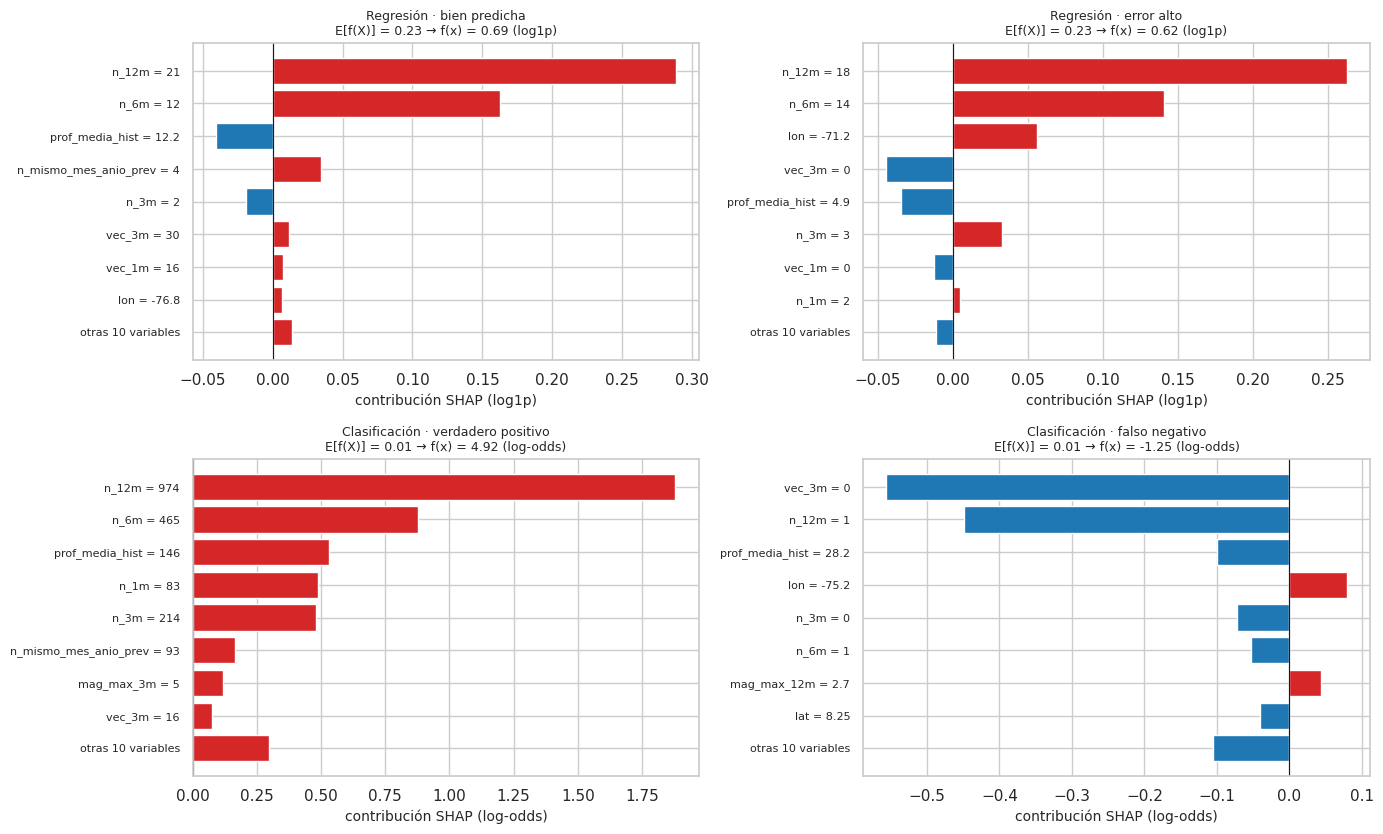

In [8]:
# Explicaciones locales SHAP (waterfall) de los cuatro casos
fig, axs = plt.subplots(2, 2, figsize=(14, 8.5))
Xraw = X.iloc[te]
for ax, (sv_exp, Xt, i, tit, esc) in zip(axs.flat, [(exp_r, Xte_r, i_bien_r, "Regresión · bien predicha", "log1p"), (exp_r, Xte_r, i_mal_r, "Regresión · error alto", "log1p"),
                                                     (exp_c, Xte_c, i_bien_c, "Clasificación · verdadero positivo", "log-odds"), (exp_c, Xte_c, i_mal_c, "Clasificación · falso negativo", "log-odds")]):
    e = sv_exp(pd.DataFrame(Xt[[i]], columns=nombres))[0]
    o = np.argsort(-np.abs(e.values))[:8][::-1]
    resto = e.values.sum() - e.values[o].sum()
    vals = np.concatenate([[resto], e.values[o]])
    etiquetas = [f"otras {len(nombres) - 8} variables"] + [f"{nombres[j]} = {Xraw.iloc[i][nombres[j]]:.3g}" for j in o]
    ax.barh(range(len(vals)), vals, color=np.where(vals >= 0, "#d62728", "#1f77b4"))
    ax.set_yticks(range(len(vals))); ax.set_yticklabels(etiquetas, fontsize=8); ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{tit}\nE[f(X)] = {e.base_values:.2f} → f(x) = {e.base_values + e.values.sum():.2f} ({esc})", fontsize=9)
    ax.set_xlabel(f"contribución SHAP ({esc})")
plt.tight_layout(); eda.guardar_figura(fig, "e2_shap_local.png"); plt.show()

Cada barra es el valor SHAP de una variable (rojo: empuja la predicción hacia arriba; azul: hacia abajo); las
etiquetas muestran el valor **original** de la variable. Por eficiencia, E[f(X)] más la suma de las barras es
exactamente la predicción f(x) del modelo en su escala (log1p o log-odds).

In [9]:
# Lectura de las explicaciones locales
def top_shap(sv_exp, Xt, i, k=3):
    e = sv_exp(pd.DataFrame(Xt[[i]], columns=nombres))[0]
    o = np.argsort(-np.abs(e.values))[:k]
    return ", ".join(f"{nombres[j]} = {X.iloc[te].iloc[i][nombres[j]] if nombres[j] in X.columns else Xt[i, j]:.3g} ({e.values[j]:+.2f})" for j in o)

md(f"- **Regresión, bien predicha** (observado {casos.observado[0]:.0f}, predicho {casos.predicho[0]:.2f}): las contribuciones principales "
   f"son {top_shap(exp_r, Xte_r, i_bien_r)}. La historia reciente de la celda es coherente con lo que ocurrió.\n"
   f"- **Regresión, error alto** (observado {casos.observado[1]:.0f}, predicho {casos.predicho[1]:.2f}): {top_shap(exp_r, Xte_r, i_mal_r)}. "
   + ("Las variables empujan hacia un valor bajo porque la celda venía tranquila" if exp_r(pd.DataFrame(Xte_r[[i_mal_r]], columns=nombres))[0].values.sum() < 0
      else "La celda tenía actividad moderada en el último año y el modelo predijo cerca de un sismo")
   + f"; el error viene de un **pico** de {casos.observado[1]:.0f} sismos en el mes objetivo (el inicio de un enjambre), algo que ninguna "
   f"variable disponible al cierre del mes t podía anunciar (cap. 18.2).\n"
   f"- **Clasificación, verdadero positivo** (probabilidad {casos.predicho[2]:.2f}): {top_shap(exp_c, Xte_c, i_bien_c)}.\n"
   f"- **Clasificación, falso negativo** (probabilidad {casos.predicho[3]:.3f}): {top_shap(exp_c, Xte_c, i_mal_c)}. Las "
   f"señales de actividad reciente estaban apagadas: es un evento sin precursores en las variables.")

- **Regresión, bien predicha** (observado 1, predicho 1.00): las contribuciones principales son n_12m = 21 (+0.29), n_6m = 12 (+0.16), prof_media_hist = 12.2 (-0.04). La historia reciente de la celda es coherente con lo que ocurrió.
- **Regresión, error alto** (observado 26, predicho 0.86): n_12m = 18 (+0.26), n_6m = 14 (+0.14), lon = -71.2 (+0.06). La celda tenía actividad moderada en el último año y el modelo predijo cerca de un sismo; el error viene de un **pico** de 26 sismos en el mes objetivo (el inicio de un enjambre), algo que ninguna variable disponible al cierre del mes t podía anunciar (cap. 18.2).
- **Clasificación, verdadero positivo** (probabilidad 0.99): n_12m = 974 (+1.88), n_6m = 465 (+0.88), prof_media_hist = 146 (+0.53).
- **Clasificación, falso negativo** (probabilidad 0.223): vec_3m = 0 (-0.56), n_12m = 1 (-0.45), prof_media_hist = 28.2 (-0.10). Las señales de actividad reciente estaban apagadas: es un evento sin precursores en las variables.

## 19.3 SHAP frente a LIME en XGBoost

**Diferencias metodológicas.**

| | SHAP (TreeSHAP) | LIME |
|---|---|---|
| Qué calcula | valores de Shapley **exactos** del modelo de árboles | coeficientes de una **regresión lineal local** ajustada a perturbaciones alrededor de x |
| Garantías | eficiencia, simetría, aditividad, consistencia | ninguna: depende del muestreo, del ancho del núcleo y de la discretización |
| Estabilidad | determinista | aleatoria (cambia con la semilla y el número de muestras) |
| Global | sí, agregando valores locales coherentes | solo agregando explicaciones locales independientes |

**Cuándo divergen.** (i) Cuando el modelo es muy **no lineal** cerca de x (los árboles tienen cortes
abruptos y LIME promedia a través de ellos); (ii) cuando hay **variables correlacionadas** (LIME perturba cada
variable de forma independiente y crea puntos fuera de la distribución, p. ej. muchos sismos en el último mes
pero cero en los últimos tres); (iii) cuando el **ancho del núcleo** no coincide con la escala de la
no linealidad; (iv) con interacciones, que SHAP reparte y LIME ignora.

**Un detalle que cambia todo en LIME.** Por defecto, `LimeTabularExplainer` genera las perturbaciones
alrededor de la **media del entrenamiento**, no de la observación (`sample_around_instance=False`). Para una
celda muy activa (cientos de sismos en el año, muy lejos de la media), todas las perturbaciones caen lejos de
ella, el núcleo les da peso casi nulo y la regresión local devuelve coeficientes ≈ 0: la «explicación» no dice
nada de esa celda. Aquí se usa `sample_around_instance=True` para que LIME sea realmente local. Es un ejemplo
del punto (iii): con LIME, los hiperparámetros del muestreo deciden la explicación.

Se comparan en las dos observaciones de regresión y en 40 observaciones aleatorias de la prueba: coincidencia
de las 5 variables principales y correlación de Spearman entre |SHAP| y |peso LIME|.

In [10]:
# SHAP frente a LIME en XGBoost: concordancia de signos y rangos en varias observaciones
lime_r = LimeTabularExplainer(Xtr_r[rng.choice(len(Xtr_r), 5000, replace=False)], feature_names=nombres, mode="regression",
                              discretize_continuous=False, sample_around_instance=True, random_state=cfg.SEMILLA)
f_r = lambda Z: xgb_r.predict(Z)                                            # noqa: E731 — misma escala (log1p) que SHAP

def comparar(i, num_samples=3000):
    e_s = exp_r(pd.DataFrame(Xte_r[[i]], columns=nombres))[0].values
    e_l = lime_r.explain_instance(Xte_r[i], f_r, num_features=len(nombres), num_samples=num_samples)
    w = np.zeros(len(nombres))
    for j, v in e_l.as_map()[1]:
        w[j] = v
    top_s, top_l = set(np.argsort(-np.abs(e_s))[:5]), set(np.argsort(-np.abs(w))[:5])
    return e_s, w, len(top_s & top_l) / 5, stats.spearmanr(np.abs(e_s), np.abs(w))[0]

filas = []
for nom, i in (("bien predicha", i_bien_r), ("error alto", i_mal_r)):
    e_s, w, ov, rh = comparar(i)
    for j in np.argsort(-np.abs(e_s))[:6]:
        filas.append({"observación": nom, "variable": nombres[j], "SHAP": e_s[j], "LIME": w[j]})
CMP = pd.DataFrame(filas)
acuerdo = [comparar(i)[2:] for i in rng.choice(len(te), 40, replace=False)]
AC = pd.DataFrame(acuerdo, columns=["coincidencia_top5", "spearman_abs"])
eda.guardar_tabla(CMP, "e2_shap_vs_lime.csv")
CMP.round(4)

,observación,variable,SHAP,LIME
0,bien predicha,n_12m,0.2886,0.1072
1,bien predicha,n_6m,0.1625,0.1014
2,bien predicha,prof_media_hist,-0.0405,-0.0089
3,bien predicha,n_mismo_mes_anio_prev,0.0345,0.0132
4,bien predicha,n_3m,-0.0193,0.0391
5,bien predicha,vec_3m,0.0118,0.0054
6,error alto,n_12m,0.2624,0.1297
7,error alto,n_6m,0.1406,0.1103
8,error alto,lon,0.0563,0.0342
9,error alto,vec_3m,-0.0441,0.0072


In [11]:
md(f"En 40 observaciones aleatorias, las 5 variables principales coinciden en promedio en un {100 * AC.coincidencia_top5.mean():.0f} % "
   f"y la correlación de Spearman entre las magnitudes es {AC.spearman_abs.mean():.2f} (mín {AC.spearman_abs.min():.2f}). "
   + ("SHAP y LIME coinciden en lo esencial (qué variables importan), " if AC.coincidencia_top5.mean() >= 0.6 else
      "SHAP y LIME discrepan bastante, ")
   + "pero sus números **no significan lo mismo**. El peso de LIME es una **pendiente local** (cuánto cambia la predicción por unidad de la "
   "variable estandarizada); el valor SHAP es una **contribución** respecto de la predicción media. "
   + (lambda r: f"En la observación de error alto, {r.variable} tiene SHAP {r.SHAP:+.2f} y peso LIME {r.LIME:+.3f}: "
      + ("tienen signo distinto, y las dos cosas pueden ser ciertas a la vez (la contribución compara con la celda media; la pendiente "
         "dice qué pasaría si la variable cambiara un poco). " if np.sign(r.SHAP) != np.sign(r.LIME) else
         "coinciden en el signo, pero no en la escala, porque miden cosas distintas. "))(CMP[CMP["observación"] == "error alto"].iloc[0])
   + "Además, LIME reparte el peso de forma distinta entre variables correlacionadas (los conteos de 1, 3 y 12 meses): la regresión lineal "
   "local no puede separar efectos de variables que se mueven juntas y las perturba por separado, generando puntos fuera de la "
   "distribución. Como TreeSHAP es exacto y determinista para XGBoost, se toma como referencia; LIME sirve para confirmar que la "
   "explicación no es un artefacto del método.")

En 40 observaciones aleatorias, las 5 variables principales coinciden en promedio en un 69 % y la correlación de Spearman entre las magnitudes es 0.62 (mín 0.15). SHAP y LIME coinciden en lo esencial (qué variables importan), pero sus números **no significan lo mismo**. El peso de LIME es una **pendiente local** (cuánto cambia la predicción por unidad de la variable estandarizada); el valor SHAP es una **contribución** respecto de la predicción media. En la observación de error alto, n_12m tiene SHAP +0.26 y peso LIME +0.130: coinciden en el signo, pero no en la escala, porque miden cosas distintas. Además, LIME reparte el peso de forma distinta entre variables correlacionadas (los conteos de 1, 3 y 12 meses): la regresión lineal local no puede separar efectos de variables que se mueven juntas y las perturba por separado, generando puntos fuera de la distribución. Como TreeSHAP es exacto y determinista para XGBoost, se toma como referencia; LIME sirve para confirmar que la explicación no es un artefacto del método.

## 19.4 Interpretación del modelo propuesto A+B v2

A+B v2 predice, en escala log1p, **ŷ = Σ_j w_j(z) · f_j(x)**, donde f_j es la predicción del miembro j y w_j(z)
su peso, que depende del contexto z de la celda (cap. 22). Como los pesos suman 1 y la predicción es una suma
ponderada, la contribución **w_j·f_j** de cada miembro suma exactamente la predicción (propiedad de eficiencia);
para llegar hasta las variables, la parte de cada miembro de árboles se abre con su propio SHAP (aditividad de
Shapley), y la de B con su estructura de árboles. La calibración final (c₀ + c₁·ŷ, cap. 22.1) es una recta, así
que solo reescala todas las contribuciones por el mismo factor c₁ y suma la constante c₀: no cambia su orden ni
sus proporciones. La tabla muestra el peso medio de cada miembro en cada origen anual del origen móvil.

In [12]:
# Contribución de cada miembro al modelo A+B v2 (pesos medios por año)
mv = pd.read_csv(r2.OM / "pesos_v2.csv").miembro.values
Wa = pd.DataFrame({a: np.load(r2.OM / "final" / f"origen_{a}.npz")["pesos"] for a in r2.ANIOS_OM}, index=mv)
Wa["media 2021–2026"] = Wa.mean(1)
Wa = Wa.sort_values("media 2021–2026", ascending=False)
eda.guardar_tabla(Wa.reset_index().rename(columns={"index": "miembro"}), "e2_ab2_contribuciones.csv")
Wa.round(3)

,2021,2022,2023,2024,2025,2026,media 2021–2026
B,0.394,0.373,0.255,0.407,0.331,0.415,0.362
XGBoost · Genético (DEAP),0.005,0.304,0.385,0.563,0.378,0.525,0.360
Random Forest · Genético (DEAP),0.532,0.314,0.359,0.011,0.289,0.003,0.251
Persistencia,0.030,0.000,0.000,0.000,0.000,0.029,0.010
Estacional,0.025,0.000,0.000,0.000,0.000,0.021,0.008
XGBoost · Random,0.000,0.008,0.000,0.007,0.002,0.003,0.003
Random Forest · Random,0.012,0.000,0.000,0.001,0.000,0.000,0.002
XGBoost · Bayesiano (TPE),0.001,0.001,0.000,0.007,0.000,0.003,0.002
Random Forest · Bayesiano (TPE),0.001,0.000,0.000,0.002,0.000,0.001,0.001
XGBoost · Grid,0.000,0.000,0.000,0.001,0.000,0.000,0.000


In [13]:
# Lectura de las contribuciones
w = Wa["media 2021–2026"]
clave_b = [k for k in w.index if k.startswith("B")][0]
otros = ", ".join(f"{m} ({100 * v:.0f} %)" for m, v in w.drop(clave_b).iloc[:3].items())
md(f"- **Global.** El peso del **modelo propio B (boosting ZINB)** es {100 * w[clave_b]:.0f} % en promedio; le siguen {otros}. Los demás "
   f"miembros reciben pesos pequeños: el combinador se queda con pocas versiones de árboles porque son muy parecidas entre sí.\n"
   f"- **Estabilidad.** El peso de B va de {100 * Wa.loc[clave_b, r2.ANIOS_OM].min():.0f} % a {100 * Wa.loc[clave_b, r2.ANIOS_OM].max():.0f} % "
   f"entre orígenes: la importancia del componente propio no depende de un año en particular.\n"
   f"- **Por variables.** Como los miembros de árboles y B usan las mismas variables dominantes (19.1), la explicación de A+B v2 por "
   f"variables es, en lo esencial, la de sus miembros: la historia reciente de conteos de la celda.")

- **Global.** El peso del **modelo propio B (boosting ZINB)** es 36 % en promedio; le siguen XGBoost · Genético (DEAP) (36 %), Random Forest · Genético (DEAP) (25 %), Persistencia (1 %). Los demás miembros reciben pesos pequeños: el combinador se queda con pocas versiones de árboles porque son muy parecidas entre sí.
- **Estabilidad.** El peso de B va de 26 % a 41 % entre orígenes: la importancia del componente propio no depende de un año en particular.
- **Por variables.** Como los miembros de árboles y B usan las mismas variables dominantes (19.1), la explicación de A+B v2 por variables es, en lo esencial, la de sus miembros: la historia reciente de conteos de la celda.

## 19.5 Conclusiones del capítulo

- Las predicciones de ambos XGBoost se explican sobre todo por la **actividad reciente de la celda**; el
  calendario y la ubicación pesan poco.
- Los errores grandes son inicios de enjambre sin precursores en las variables: el modelo se equivoca por
  falta de información, no por una relación mal aprendida.
- SHAP y LIME coinciden en las variables principales; LIME es menos estable y reparte distinto el peso entre
  variables correlacionadas, por lo que SHAP es la referencia.
- A+B v2 se explica por sus pesos por miembro; el mayor peso está en el modelo propio B en todos los orígenes.